# Baseline de vídeo: personas, caras y tiempo en pantalla

**Reto Mujeres por la IA Abierta · Sesión de visión por computador**

Este notebook es el *pipeline* base que aparece en las slides (bloque 8). **Es un punto de partida, no una solución**: es deliberadamente simple y tiene errores conocidos. El reto consiste en mejorarlo.

| Paso | Qué hace | Herramienta |
|---|---|---|
| 1 | Detectar personas y seguirlas en el tiempo (cada persona recibe un número de *track*) | YOLO + ByteTrack |
| 2 | Detectar caras, estimar el **género percibido** y votar entre fotogramas para cada *track* | InsightFace |
| 3 | Calcular medidas por persona (tiempo en pantalla, tamaño, centralidad) y el % por grupo | pandas |

**Antes de ejecutar:** en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*. También funciona en CPU, pero más despacio. Después, *Ejecutar todo*.

**Avisos importantes**
- Los modelos de cara **no ven la identidad de género**: predicen cómo se *percibe* una cara según las etiquetas (binarias) de sus datos de entrenamiento. Tratad la salida como una estimación incierta y mantened una categoría `unknown`.
- Los modelos preentrenados de InsightFace tienen **licencia de uso solo para investigación no comercial**. Ultralytics YOLO tiene licencia AGPL-3.0.
- Vídeo de ejemplo: *Intel IoT DevKit sample videos*, `face-demographics-walking-and-pause.mp4`, licencia **CC BY 4.0**.

In [ ]:
!pip install -q ultralytics lap insightface onnxruntime-gpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 109.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 79.1 MB/s eta 0:00:00


## 0. El vídeo

Descargamos el vídeo de ejemplo y lo mostramos. Para usar un vídeo vuestro, subidlo al panel de archivos de la izquierda y cambiad `VIDEO`.

In [1]:
import cv2, subprocess, urllib.request
from IPython.display import Video, display

VIDEO = "face-demographics-walking-and-pause.mp4"     # <- cambiad aquí para usar otro vídeo
if VIDEO == "face-demographics-walking-and-pause.mp4":
    urllib.request.urlretrieve("https://raw.githubusercontent.com/intel-iot-devkit/sample-videos/master/face-demographics-walking-and-pause.mp4", VIDEO)

cap = cv2.VideoCapture(VIDEO)
FPS, W, H = cap.get(cv2.CAP_PROP_FPS), int(cap.get(3)), int(cap.get(4))
print(f"{FPS:.0f} fps, {W}x{H}, {cap.get(cv2.CAP_PROP_FRAME_COUNT) / FPS:.0f} s")

# convert to H.264 so that the browser can play it
subprocess.run(f"ffmpeg -y -loglevel error -i {VIDEO} -vcodec libx264 -pix_fmt yuv420p input_h264.mp4", shell=True)
display(Video("input_h264.mp4", embed=True, width=640))

12 fps, 768x432, 91 s


## 1. Paso 1: detectar y seguir personas (YOLO + ByteTrack)

No analizamos todos los fotogramas: con `STRIDE = 4` nos quedamos con 1 de cada 4 (3 por segundo en este vídeo de 12 fps).

In [3]:
! pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.9 MB/s eta 0:00:00


In [4]:
import pandas as pd
from ultralytics import YOLO

STRIDE = 4
model = YOLO("yolo11m.pt")                     # pretrained on COCO: class 0 = person
results = model.track(VIDEO, classes=[0], tracker="bytetrack.yaml",
                      vid_stride=STRIDE, stream=True, verbose=False)
rows = []
for f, r in enumerate(results):              # f = index of the analysed frame
    for b in r.boxes:
        if b.id is None: continue
        x1, y1, x2, y2 = b.xyxy[0].tolist()
        rows.append(dict(frame=f, track=int(b.id), conf=float(b.conf),
                         x1=x1, y1=y1, x2=x2, y2=y2))
df = pd.DataFrame(rows)
print(len(df), "detections,", df.track.nunique(), "tracks")
df.head()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 276ms
Prepared 1 package in 55ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

278 detections, 7 tracks


,frame,track,conf,x1,y1,x2,y2
0,10,1,0.893086,498.059540,178.762115,540.769226,394.272339
1,11,1,0.906386,487.234436,174.261719,533.712646,405.391357
2,12,1,0.903735,464.628235,175.050781,515.876099,424.558746
3,13,1,0.903726,441.924774,170.539062,496.957733,431.563812
4,14,1,0.919036,416.444489,170.009293,473.909912,432.000000


## 2. Paso 2: caras y género percibido por *track* (InsightFace)

Para cada fotograma analizado detectamos las caras, asignamos cada cara a la caja de persona que la contiene y guardamos el voto (`F` / `M`). Al final, cada *track* recibe una etiqueta solo si hay al menos 2 caras y el 80 % de los votos coincide; si no, `unknown`.

In [ ]:
from collections import Counter
from insightface.app import FaceAnalysis

app = FaceAnalysis(name="buffalo_l", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
app.prepare(ctx_id=0, det_size=(640, 640))

votes = {t: [] for t in df.track.unique()}
faces_per_frame = {}
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE); ok, frame = cap.read()
    if not ok: continue
    people = df[df.frame == f]
    faces_per_frame[f] = []
    for fc in app.get(frame):                # frame in BGR, as read by OpenCV
        faces_per_frame[f].append((fc.bbox, fc.sex, int(fc.age)))
        cx, cy = (fc.bbox[0] + fc.bbox[2]) / 2, (fc.bbox[1] + fc.bbox[3]) / 2
        inside = people[(people.x1 <= cx) & (cx <= people.x2) & (people.y1 <= cy) & (cy <= people.y2)]
        if len(inside):                      # smallest person box that contains the face
            t = inside.loc[(inside.x2 - inside.x1).idxmin(), "track"]
            votes[t].append(fc.sex)

def vote(v, min_faces=2, min_agree=0.8):
    if len(v) < min_faces: return "unknown"
    label, n = Counter(v).most_common(1)[0]
    return label if n / len(v) >= min_agree else "unknown"

track_gender = {int(t): vote(v) for t, v in votes.items()}
for t, v in votes.items():
    print(f"track {t}: votes {dict(Counter(v))} -> {track_gender[int(t)]}")

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:03<00:00, 80689.91KB/s]
/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


track 1: votes {'F': 1, 'M': 45} -> M
track 3: votes {'F': 38, 'M': 8} -> F
track 4: votes {'M': 42} -> M
track 8: votes {'M': 8, 'F': 28} -> unknown
track 9: votes {'F': 15, 'M': 22} -> unknown
track 11: votes {'M': 34} -> M
track 12: votes {'M': 1, 'F': 32} -> F


## 3. Paso 3: de los *tracks* a las medidas

In [ ]:
FPS_SAMPLED = FPS / STRIDE
df["area"] = (df.x2 - df.x1) * (df.y2 - df.y1) / (W * H)     # fraction of the frame
df["cx"]   = (df.x1 + df.x2) / 2 / W                          # horizontal centre, 0..1

per_track = df.groupby("track").agg(
    frames=("frame", "nunique"), area=("area", "mean"),
    centrality=("cx", lambda c: 1 - 2 * (c - 0.5).abs().mean()))
per_track["screen_time_s"] = per_track.frames / FPS_SAMPLED
per_track["gender"] = per_track.index.map(track_gender)
display(per_track.round(2))

share = per_track.groupby("gender").screen_time_s.sum()
print("% of screen time by predicted label:")
print((100 * share / share.sum()).round(1))

,frames,area,centrality,screen_time_s,gender
track,,,,,
1,47,0.19,0.94,15.67,M
3,46,0.15,0.48,15.33,F
4,43,0.28,0.76,14.33,M
8,37,0.13,0.51,12.33,unknown
9,37,0.13,0.59,12.33,unknown
11,35,0.18,0.93,11.67,M
12,33,0.21,0.84,11.00,F


% of screen time by predicted label:
gender
F          28.4
M          45.0
unknown    26.6
Name: screen_time_s, dtype: float64


## 4. Ver el resultado: vídeo anotado

Dibujamos sobre cada fotograma analizado la caja de cada persona (morado = `F`, azul = `M`, gris = `unknown`) y la cara con lo que predice el modelo en *ese* fotograma. Fijaos en cuándo la predicción de la cara cambia de un fotograma a otro.

In [ ]:
COL = {"F": (161, 86, 99), "M": (176, 143, 46), "unknown": (150, 150, 150)}   # BGR
vw = cv2.VideoWriter("annot_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS_SAMPLED, (W, H))
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE); ok, frame = cap.read()
    for _, r in df[df.frame == f].iterrows():
        g = track_gender[int(r.track)]; c = COL[g]
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, 3)
        lab = f"person {int(r.track)} | {g}"
        (tw, th), _ = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x1) + tw + 10, int(r.y1) + th + 12), c, -1)
        cv2.putText(frame, lab, (int(r.x1) + 5, int(r.y1) + th + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    for bb, sex, age in faces_per_frame.get(f, []):
        x1, y1, x2, y2 = map(int, bb)
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 255, 255), 2)
        cv2.putText(frame, f"face {sex} ~{age}y", (x1, y2 + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    cv2.putText(frame, f"t = {f * STRIDE / FPS:4.1f} s", (12, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    vw.write(frame)
vw.release()
subprocess.run("ffmpeg -y -loglevel error -i annot_raw.mp4 -vcodec libx264 -pix_fmt yuv420p annotated.mp4", shell=True)
display(Video("annotated.mp4", embed=True, width=640))

## 5. Gráficos

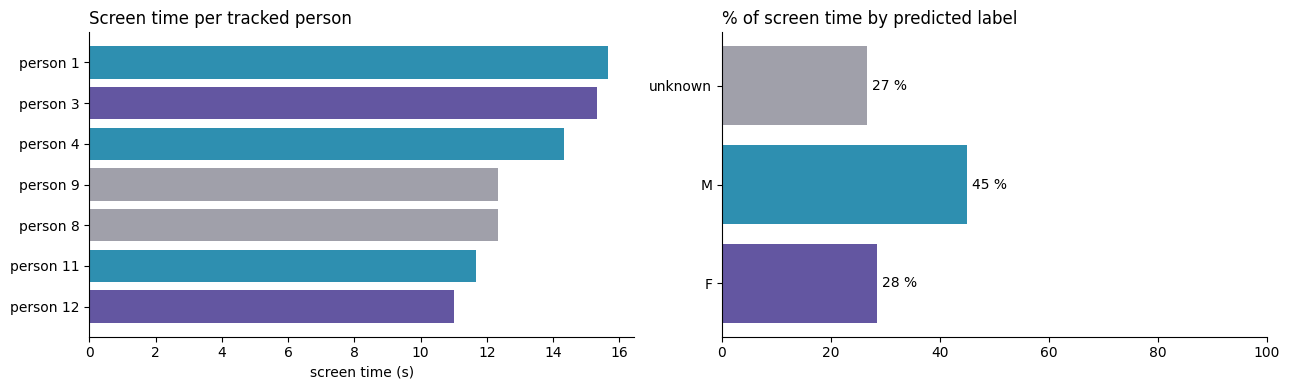

In [ ]:
import matplotlib.pyplot as plt
P = {"F": "#6356A1", "M": "#2E8FB0", "unknown": "#A0A0AA"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
pt = per_track.sort_values("screen_time_s")
a1.barh([f"person {t}" for t in pt.index], pt.screen_time_s, color=[P[g] for g in pt.gender])
a1.set_xlabel("screen time (s)"); a1.set_title("Screen time per tracked person", loc="left")
sh = 100 * share / share.sum()
a2.barh(list(sh.index), sh.values, color=[P[g] for g in sh.index])
for y, v in enumerate(sh.values): a2.text(v + 1, y, f"{v:.0f} %", va="center")
a2.set_xlim(0, 100); a2.set_title("% of screen time by predicted label", loc="left")
for a in (a1, a2):
    for s in ["top", "right"]: a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## ¿Y ahora qué?

Mirad el vídeo anotado y comparad con lo que veis vosotras: ¿cuántas mujeres y cuántos hombres aparecen? ¿Coincide con el resultado?

Algunas ideas para mejorar el *baseline*:
- **Definición:** ¿qué significa "protagonista"? Tiempo en pantalla, tamaño, centralidad, planos, mirada a cámara, si habla…
- **Percepción:** caras pequeñas o de perfil, unir *tracks* de la misma persona (re-identificación), detección de cortes de plano.
- **Multimodal:** combinar con el audio (quién habla) y con el texto (quién es nombrado, rótulos).
- **Incertidumbre y sesgo:** medir los errores por subgrupo; no esconder la categoría `unknown`.
- **Evaluación:** anotad a mano una muestra de *vuestro* contenido y medid el error de la medida final.